**A. Predict the price of the Uber ride from a given pickup point to the agreed drop-off location. Perform following tasks:
1. Pre-process the dataset.
2. Identify outliers.
3. Check the correlation.
4. Implement linear regression and ridge, Lasso regression models.
5. Evaluate the models and compare their respective scores like R2, RMSE, etc.
Dataset link: https://www.kaggle.com/datasets/yasserh/uber-fares-dataset**

In [2]:
!pip install pandas seaborn scikit-learn numpy matplotlib


[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline,make_pipeline
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score


In [5]:
df=pd.read_csv("uber.csv")
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [6]:
df.shape

(200000, 9)

In [7]:
df.info

<bound method DataFrame.info of         Unnamed: 0                            key  fare_amount  \
0         24238194    2015-05-07 19:52:06.0000003          7.5   
1         27835199    2009-07-17 20:04:56.0000002          7.7   
2         44984355   2009-08-24 21:45:00.00000061         12.9   
3         25894730    2009-06-26 08:22:21.0000001          5.3   
4         17610152  2014-08-28 17:47:00.000000188         16.0   
...            ...                            ...          ...   
199995    42598914   2012-10-28 10:49:00.00000053          3.0   
199996    16382965    2014-03-14 01:09:00.0000008          7.5   
199997    27804658   2009-06-29 00:42:00.00000078         30.9   
199998    20259894    2015-05-20 14:56:25.0000004         14.5   
199999    11951496   2010-05-15 04:08:00.00000076         14.1   

                pickup_datetime  pickup_longitude  pickup_latitude  \
0       2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1       2009-07-17 20:04:56 UTC    

In [8]:
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [9]:
df.describe()

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [28]:
df.drop(["Unnamed: 0",'key'],axis=1,errors="ignore",inplace=True)


In [29]:
df
df = df.dropna().copy()


In [30]:
#convert the pickup datetime
df['pickup_datetime'].dtype
df['pickup_datetime']=pd.to_datetime(
    df['pickup_datetime'],
    errors='coerce',
    utc=True
)
df.pickup_datetime.dtype
df=df.dropna().copy()

KeyError: 'pickup_datetime'

In [ ]:
df['hour']=df['pickup_datetime'].dt.hour
df['day_of_week']=df['pickup_datetime'].dt.dayofweek
df['year']=df['pickup_datetime'].dt.year

In [ ]:
df

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day_of_week,year
0,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1,19,3,2015
1,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1,20,4,2009
2,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1,21,0,2009
3,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3,8,4,2009
4,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5,17,3,2014
...,...,...,...,...,...,...,...,...,...,...
199995,3.0,2012-10-28 10:49:00+00:00,-73.987042,40.739367,-73.986525,40.740297,1,10,6,2012
199996,7.5,2014-03-14 01:09:00+00:00,-73.984722,40.736837,-74.006672,40.739620,1,1,4,2014
199997,30.9,2009-06-29 00:42:00+00:00,-73.986017,40.756487,-73.858957,40.692588,2,0,0,2009
199998,14.5,2015-05-20 14:56:25+00:00,-73.997124,40.725452,-73.983215,40.695415,1,14,2,2015


In [ ]:
df.drop('pickup_datetime',axis=1,inplace=True)

In [ ]:
df

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day_of_week,year
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,3,2015
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,4,2009
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,0,2009
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,4,2009
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,3,2014
...,...,...,...,...,...,...,...,...,...
199995,3.0,-73.987042,40.739367,-73.986525,40.740297,1,10,6,2012
199996,7.5,-73.984722,40.736837,-74.006672,40.739620,1,1,4,2014
199997,30.9,-73.986017,40.756487,-73.858957,40.692588,2,0,0,2009
199998,14.5,-73.997124,40.725452,-73.983215,40.695415,1,14,2,2015


In [ ]:
df=df[
    (df['fare_amount'] > 0) &
    (df['passenger_count'].between(1,6)) &
    (df['pickup_latitude'].between(-90,90))&
    (df['dropoff_latitude'].between(-90,90))&
    (df['pickup_longitude'].between(-180,180))&
    (df['dropoff_longitude'].between(-180,180))
].copy()

In [ ]:
def haversine(lat1,lon1,lat2,lon2):
    R=6371
    lat1,lon1,lat2,lon2=map(
        np.radians,[lat1,lon1,lat2,lon2]
    )
    dlat=lat2-lat1
    dlon=lon2-lon1
    a=(
        np.sin(dlat/2)**2+
        np.cos(lat1)*np.cos(lat2)*
        np.sin(dlon/2)**2
    )
    a=np.clip(a,0,1)

    return 2*R*np.arcsin(np.sqrt(a))


In [ ]:
df['distance_km']=haversine(
    df['pickup_latitude'],
    df['pickup_longitude'],
    df['dropoff_latitude'],
    df['dropoff_longitude']
)

In [31]:
df.distance_km

0          1.683323
1          2.457590
2          5.036377
3          1.661683
4          4.475450
            ...    
199995     0.112210
199996     1.875050
199997    12.850319
199998     3.539715
199999     5.417783
Name: distance_km, Length: 199256, dtype: float64

In [32]:
df=df[df['distance_km'].between(0.1,100)].copy()

In [33]:
df

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day_of_week,year,distance_km
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,3,2015,1.683323
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,4,2009,2.457590
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,0,2009,5.036377
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,4,2009,1.661683
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,3,2014,4.475450
...,...,...,...,...,...,...,...,...,...,...
199995,3.0,-73.987042,40.739367,-73.986525,40.740297,1,10,6,2012,0.112210
199996,7.5,-73.984722,40.736837,-74.006672,40.739620,1,1,4,2014,1.875050
199997,30.9,-73.986017,40.756487,-73.858957,40.692588,2,0,0,2009,12.850319
199998,14.5,-73.997124,40.725452,-73.983215,40.695415,1,14,2,2015,3.539715


In [34]:
df.drop(['pickup_latitude','pickup_longitude','dropoff_latitude','dropoff_longitude'],axis=1,inplace=True)

In [35]:
df


,fare_amount,passenger_count,hour,day_of_week,year,distance_km
0,7.5,1,19,3,2015,1.683323
1,7.7,1,20,4,2009,2.457590
2,12.9,1,21,0,2009,5.036377
3,5.3,3,8,4,2009,1.661683
4,16.0,5,17,3,2014,4.475450
...,...,...,...,...,...,...
199995,3.0,1,10,6,2012,0.112210
199996,7.5,1,1,4,2014,1.875050
199997,30.9,2,0,0,2009,12.850319
199998,14.5,1,14,2,2015,3.539715


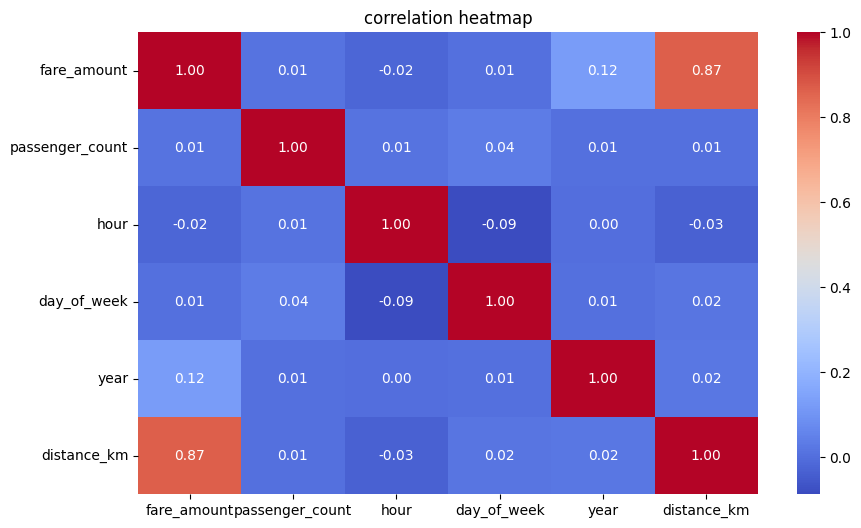

In [36]:
#check correlation
plt.figure(figsize=(10,6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("correlation heatmap")
plt.show()


In [37]:
x=df.drop('fare_amount',axis=1)
y=df['fare_amount']

In [38]:
x_train,x_test,y_train,y_test=train_test_split(
    x,y,test_size=0.2,random_state=42
)

Text(0.5, 1.0, 'Fare Amount Outliers')

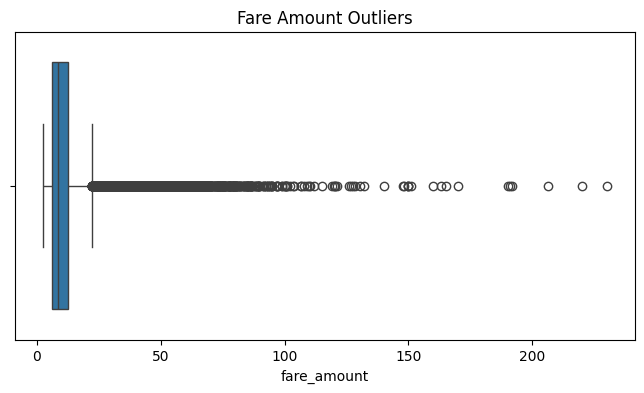

In [41]:
#Finding the Outliers
q1=y_train.quantile(0.25)
q3=y_train.quantile(0.75)
iqr=q3-q1
lower=q1 - 1.5*iqr
upper=q3 + 1.5*iqr
plt.figure(figsize=(8,4))
sns.boxplot(x=y_train)
plt.title("Fare Amount Outliers")

In [42]:
mask=y_train.between(lower,upper)
x_train=x_train.loc[mask]
y_train=y_train.loc[mask]

In [45]:
models={
    "Linear Regression":make_pipeline(
        StandardScaler(),LinearRegression()
    ),
    "Ridge  Regression":make_pipeline(
        StandardScaler(),Ridge(alpha=1.0)
    ),
    "Lasso Regression":make_pipeline(
        StandardScaler(),Lasso(alpha=0.1,max_iter=10000)
    )
}

In [53]:
results=[]
for name,model in models.items():
    model.fit(x_train,y_train)
    y_pred=model.predict(x_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    results.append([name, mae, mse, rmse, r2])

In [55]:
result_df=pd.DataFrame(
    results,
    columns=["Model","MSE","MAE","RMSE","R2 Score"]
)
result_df.round(4)

,Model,MSE,MAE,RMSE,R2 Score
0,Linear Regression,2.7643,29.2350,5.4069,0.6716
1,Ridge Regression,2.7643,29.2353,5.4070,0.6716
2,Lasso Regression,2.8400,30.5706,5.5291,0.6566


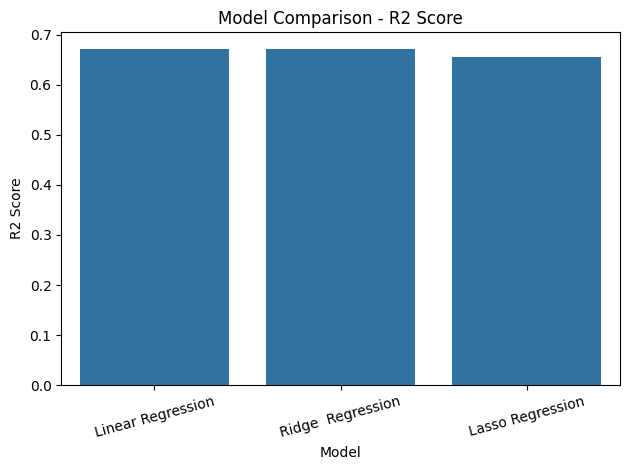

In [57]:
sns.barplot(data=result_df,x="Model",y="R2 Score")
plt.title("Model Comparison - R2 Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

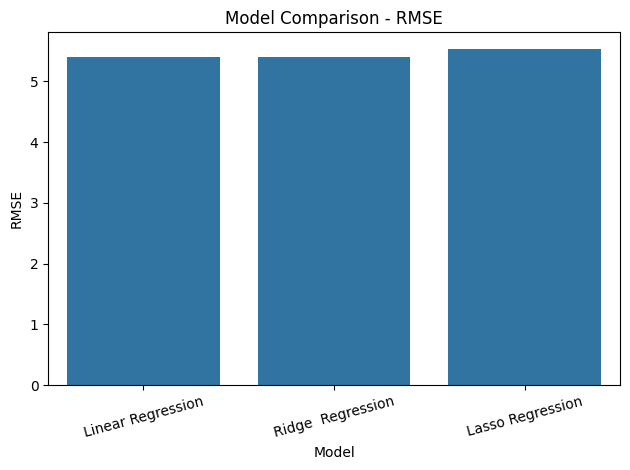

In [59]:
sns.barplot(data=result_df, x="Model", y="RMSE")
plt.title("Model Comparison - RMSE")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()